# Huấn luyện và đánh giá Ridge / Random Forest

**Notebook được chuẩn bị sẵn, chưa chạy mô hình.** Chọn kernel **Python (IT Career Insight)**,
chạy từ đầu theo thứ tự. Các cell fit, đánh giá và lưu file chỉ chạy khi bạn bấm chạy.

Bộ chính: **vn_developer v1.0.1**, train 123 / validation 25 / test 28. Mục tiêu dự đoán
trung điểm lương chào tuyển **VND/tháng, chưa rõ gross/net**, không phải thu nhập thực nhận.

Quy trình: kiểm tra snapshot → tiền xử lý trong Pipeline → baseline median → thử cấu hình
trên train, chọn bằng MAE validation → chốt mô hình → đánh giá test → biểu đồ và lưu model.
Không chia lại dữ liệu, không fit encoder/scaler trên validation/test và không chỉnh tham số
sau khi xem test. Kết quả thực tế có thể kém baseline; số mẫu hiện còn nhỏ.

Nếu notebook đang mở ở tab cũ, nạp lại bản trên ổ đĩa. Lưu notebook trước khi chạy để hash code khớp phiên bản bạn thực thi.

## 1. Môi trường, thư viện và cấu hình dữ liệu

In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys
from datetime import datetime, timezone
from uuid import uuid4

# Chạy được khi Jupyter mở từ thư mục ML hoặc ML/notebooks.
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / "configs/salary.yaml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Hãy mở notebook từ thư mục dự án ML.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

SEED = 42
SPLIT_VERSION = "v1.0.1"
sns.set_theme(style="whitegrid", font="DejaVu Sans")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

print("Python:", sys.version.split()[0])
print("Dự án:", ROOT)

import platform
import subprocess
import re
import joblib
import sklearn
import yaml
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

config = yaml.safe_load((ROOT / "configs/salary.yaml").read_text())
assert config["dataset"]["cohort"] == "vn_developer"
assert config["target"] == "salary_monthly_vnd"
assert config["seed"] == SEED
print("scikit-learn:", sklearn.__version__)
print("Target:", config["target"])


Python: 3.11.17
Dự án: /Users/scara2906/Downloads/ML


scikit-learn: 1.9.1
Target: salary_monthly_vnd


## 2. Kiểm tra checksum và đọc train/validation

Test chỉ đọc ID/nhóm ở đây để kiểm tra rò rỉ. Nhãn test chỉ được mở ở cell đánh giá cuối.
CSV đóng băng không bị ghi đè. Nếu một kiểm tra thất bại, dừng và kiểm tra phiên bản dữ liệu.

In [2]:
MANIFEST_PATH = ROOT / config["dataset"]["manifest"]
FROZEN_PATH = ROOT / config["dataset"]["frozen"]
manifest = json.loads(MANIFEST_PATH.read_text())
frozen = json.loads(FROZEN_PATH.read_text())
assert sha256_file(ROOT / frozen["manifest_path"]) == frozen["manifest_sha256"]
snapshot = json.loads((ROOT / frozen["manifest_path"]).read_text())
assert next(c for c in snapshot["cohorts"] if c["cohort"] == "vn_developer") == manifest
assert manifest["split_prepared"] and manifest["currency"] == "VND"
assert manifest["target"] == "salary_monthly_vnd"
assert manifest["target_definition"] == "advertised_salary_midpoint"

for split in ["train", "valid", "test"]:
    info = manifest["files"][split]
    path = ROOT / config["dataset"][split]
    assert path.resolve() == (ROOT / info["path"]).resolve()
    assert sha256_file(path) == info["sha256"], f"Checksum khác: {split}"

train_df = pd.read_csv(ROOT / config["dataset"]["train"])
valid_df = pd.read_csv(ROOT / config["dataset"]["valid"])
test_ids = pd.read_csv(ROOT / config["dataset"]["test"],
                       usecols=["record_id", "leakage_group_id"])
frames_for_identity = {"train": train_df, "valid": valid_df, "test": test_ids}
for name, frame in frames_for_identity.items():
    assert len(frame) == manifest["files"][name]["rows"]
    assert frame["record_id"].is_unique
for left, right in [("train", "valid"), ("train", "test"), ("valid", "test")]:
    assert set(frames_for_identity[left]["record_id"]).isdisjoint(
        frames_for_identity[right]["record_id"])
    assert set(frames_for_identity[left]["leakage_group_id"]).isdisjoint(
        frames_for_identity[right]["leakage_group_id"])
print("Train / validation / test:", len(train_df), len(valid_df), len(test_ids))
print("Đã kiểm tra ID/nhóm; chưa đọc nhãn test.")


Train / validation / test: 123 25 28
Đã kiểm tra ID/nhóm; chưa đọc nhãn test.


## 3. Tách features và target; không dùng ID/nguồn làm feature

In [3]:
numeric_cols = list(config["numeric_features"])
categorical_cols = list(config["categorical_features"])
skill_cols = list(config["multilabel_features"])
assert skill_cols == ["skills"]
feature_cols = numeric_cols + categorical_cols + skill_cols
assert feature_cols == ["experience_years", "role", "level", "location", "skills"]
target_col = config["target"]
forbidden = {"record_id", "source_dataset", "source_row_index", "group_id", "leakage_group_id",
             "salary_min", "salary_max", "salary_raw", "description", "title", target_col}
assert not set(feature_cols) & forbidden

def features_from(frame):
    result = frame[feature_cols].copy()
    for col in numeric_cols:
        result[col] = pd.to_numeric(result[col], errors="raise").astype(float)
        assert result[col].dropna().ge(0).all(), "Kinh nghiệm âm không hợp lệ."
    for col in categorical_cols + skill_cols:
        result[col] = result[col].astype(object).where(result[col].notna(), np.nan)
    return result

X_train, X_valid = features_from(train_df), features_from(valid_df)
y_train = train_df[target_col].astype(float)
y_valid = valid_df[target_col].astype(float)
assert np.isfinite(y_train).all() and y_train.gt(0).all()
assert np.isfinite(y_valid).all() and y_valid.gt(0).all()
display(pd.DataFrame({"rows": [len(X_train), len(X_valid)],
                      "features": [X_train.shape[1], X_valid.shape[1]]}, index=["train", "valid"]))
display(X_train.isna().sum().to_frame("missing_train"))


,rows,features
train,123,5
valid,25,5


,missing_train
experience_years,0
role,0
level,79
location,0
skills,0


## 4. Pipeline tiền xử lý

Kinh nghiệm: median + scaler. Danh mục: điền Unknown + one-hot, bỏ qua category chưa thấy.
Kỹ năng: một token cho cả tên kỹ năng, phân cách bằng `;`; giữ C++, C#, Node.js và cụm từ
nhiều tiếng. Pipeline dùng regex/NumPy có thể lưu/nạp bằng joblib, không phụ thuộc hàm
tokenizer định nghĩa trong notebook. Mỗi ứng viên clone bộ xử lý và fit **chỉ train**.

In [4]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown", keep_empty_features=True)),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])
skills_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="__missing_skill__",
                              keep_empty_features=True)),
    ("flatten", FunctionTransformer(np.ravel, feature_names_out="one-to-one")),
    ("vectorizer", CountVectorizer(tokenizer=re.compile(r"[^;\s](?:[^;]*[^;\s])?").findall, token_pattern=None,
                                    lowercase=True, binary=True)),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols),
    ("skills", skills_pipeline, ["skills"]),
], remainder="drop")

def make_model(regressor):
    return Pipeline([("preprocess", clone(preprocessor)), ("model", regressor)])

print("Đã khai báo Pipeline; cell này chưa fit.")


Đã khai báo Pipeline; cell này chưa fit.


## 5. Khai báo trước phạm vi thử nghiệm và nơi lưu

Đây là grid nhỏ để bắt đầu, không phải cấu hình tối ưu đã được chứng minh. Chọn bằng MAE
validation; không dùng điểm test để sửa grid. Random Forest chạy CPU, `n_jobs=1`, seed 42.
Artifact được gắn hash code notebook + dữ liệu + cấu hình. Chạy lại đúng protocol sẽ dùng
lại kết quả test đã lưu thay vì đánh giá test thêm lần nữa.

In [5]:
RIDGE_ALPHAS = [0.1, 1.0, 10.0, 100.0]
RF_DEPTHS = [None, 6]
RF_MIN_LEAVES = [2, 5]
RF_TREES = 300
PRIMARY_METRIC = "mae_vnd"

NOTEBOOK_PATH = ROOT / "notebooks/02_salary_models.ipynb"
disk_notebook = json.loads(NOTEBOOK_PATH.read_text())
notebook_code = "\n\n".join("".join(cell["source"]) for cell in disk_notebook["cells"]
                                  if cell["cell_type"] == "code")
NOTEBOOK_CODE_SHA = hashlib.sha256(notebook_code.encode()).hexdigest()
protocol = {
    "dataset_manifest_sha256": sha256_file(MANIFEST_PATH),
    "frozen_snapshot_sha256": frozen["manifest_sha256"],
    "notebook_code_sha256": NOTEBOOK_CODE_SHA, "seed": SEED, "features": feature_cols,
    "ridge_alphas": RIDGE_ALPHAS, "rf_depths": RF_DEPTHS,
    "rf_min_samples_leaf": RF_MIN_LEAVES, "rf_trees": RF_TREES,
    "primary_metric": PRIMARY_METRIC, "fit_split": "train_only_no_refit",
    "sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__,
}
EXPERIMENT_ID = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest()[:16]
OUT = ROOT / "outputs/metrics" / f"salary_{EXPERIMENT_ID}"
MODEL_DIR = ROOT / "models/salary" / EXPERIMENT_ID
OUT.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
(OUT / "protocol.json").write_text(json.dumps(protocol, indent=2, ensure_ascii=False) + "\n")
print("Experiment:", EXPERIMENT_ID)
print("Kết quả:", OUT)
print("Model:", MODEL_DIR)


Experiment: bd9af2fa002caae8
Kết quả: /Users/scara2906/Downloads/ML/outputs/metrics/salary_bd9af2fa002caae8
Model: /Users/scara2906/Downloads/ML/models/salary/bd9af2fa002caae8


## 6. Hàm đánh giá

MAE là sai số tuyệt đối trung bình; RMSE phạt sai số lớn mạnh hơn; R² có thể âm nếu kém
mốc dự đoán trung bình. Mọi metric dùng VND/tháng, không làm tròn trước khi tính.
Đếm riêng dự đoán âm; không âm thầm cắt giá trị để làm đẹp metric.

In [6]:
def regression_metrics(actual, predicted):
    predicted = np.asarray(predicted, dtype=float)
    assert np.isfinite(predicted).all()
    return {
        "mae_vnd": float(mean_absolute_error(actual, predicted)),
        "rmse_vnd": float(root_mean_squared_error(actual, predicted)),
        "r2": float(r2_score(actual, predicted)),
        "negative_predictions": int((predicted < 0).sum()),
    }

def display_metrics(table):
    result = table.copy()
    for col in ["mae_vnd", "rmse_vnd"]:
        if col in result:
            result[col.replace("_vnd", "_million_vnd")] = result[col] / 1_000_000
    display(result)


## 7. Baseline median — **cell này bắt đầu fit khi bạn chạy**

Baseline luôn dự đoán median lương trong train. Hai mô hình phải được so với mốc này;
không mặc định mô hình phức tạp hơn sẽ tốt hơn.

In [7]:
baseline = make_model(DummyRegressor(strategy="median"))
baseline.fit(X_train, y_train)
baseline_valid_pred = baseline.predict(X_valid)
baseline_valid = regression_metrics(y_valid, baseline_valid_pred)
display_metrics(pd.DataFrame([{"model": "baseline_median", **baseline_valid}]))


,model,mae_vnd,rmse_vnd,r2,negative_predictions,mae_million_vnd,rmse_million_vnd
0,baseline_median,12510000.0,1.783823e+07,-0.063847,0,12.51,17.838231


## 8. Train Ridge và chọn alpha bằng validation

In [8]:
ridge_candidates = []
for alpha in RIDGE_ALPHAS:
    pipeline = make_model(Ridge(alpha=alpha, solver="lsqr"))
    pipeline.fit(X_train, y_train)
    metrics = regression_metrics(y_valid, pipeline.predict(X_valid))
    ridge_candidates.append({"params": {"alpha": alpha}, "pipeline": pipeline, "metrics": metrics})

best_ridge = min(ridge_candidates, key=lambda item: item["metrics"][PRIMARY_METRIC])
ridge_table = pd.DataFrame([{**item["params"], **item["metrics"]} for item in ridge_candidates])
ridge_table.to_csv(OUT / "ridge_validation_grid.csv", index=False)
display_metrics(ridge_table.sort_values(PRIMARY_METRIC))
print("Chọn Ridge:", best_ridge["params"])


,alpha,mae_vnd,rmse_vnd,r2,negative_predictions,mae_million_vnd,rmse_million_vnd
2,10.0,9.266960e+06,1.212983e+07,0.508091,0,9.266960,12.129830
3,100.0,9.858303e+06,1.370564e+07,0.371979,0,9.858303,13.705642
1,1.0,1.024684e+07,1.389147e+07,0.354834,0,10.246843,13.891466
0,0.1,1.155073e+07,1.530071e+07,0.217294,1,11.550734,15.300708


Chọn Ridge: {'alpha': 10.0}


## 9. Train Random Forest và chọn cấu hình bằng validation

In [9]:
rf_candidates = []
for depth in RF_DEPTHS:
    for leaf in RF_MIN_LEAVES:
        params = {"n_estimators": RF_TREES, "max_depth": depth,
                  "min_samples_leaf": leaf, "max_features": 1.0}
        pipeline = make_model(RandomForestRegressor(**params, random_state=SEED, n_jobs=1))
        pipeline.fit(X_train, y_train)
        metrics = regression_metrics(y_valid, pipeline.predict(X_valid))
        rf_candidates.append({"params": params, "pipeline": pipeline, "metrics": metrics})

best_rf = min(rf_candidates, key=lambda item: item["metrics"][PRIMARY_METRIC])
rf_table = pd.DataFrame([{**item["params"], **item["metrics"]} for item in rf_candidates])
rf_table.to_csv(OUT / "random_forest_validation_grid.csv", index=False)
display_metrics(rf_table.sort_values(PRIMARY_METRIC))
print("Chọn Random Forest:", best_rf["params"])


,n_estimators,max_depth,min_samples_leaf,max_features,mae_vnd,rmse_vnd,r2,negative_predictions,mae_million_vnd,rmse_million_vnd
2,300,6.0,2,1.0,8.473359e+06,1.208438e+07,0.511771,0,8.473359,12.084377
0,300,NaN,2,1.0,8.531679e+06,1.200968e+07,0.517788,0,8.531679,12.009681
3,300,6.0,5,1.0,9.002421e+06,1.211875e+07,0.508989,0,9.002421,12.118746
1,300,NaN,5,1.0,9.010936e+06,1.213141e+07,0.507963,0,9.010936,12.131409


Chọn Random Forest: {'n_estimators': 300, 'max_depth': 6, 'min_samples_leaf': 2, 'max_features': 1.0}


## 10. So sánh và chốt lựa chọn **trước khi xem test**

Mô hình được fit trên 123 dòng train; không refit lên train+validation trong lượt này để
artifact lưu lại đúng mô hình đã so sánh. Nếu baseline tốt nhất trên validation thì giữ
baseline làm lựa chọn; vẫn báo cáo Ridge và Random Forest để đánh giá đầy đủ đề tài.

In [10]:
family_models = {
    "baseline_median": baseline,
    "ridge": best_ridge["pipeline"],
    "random_forest": best_rf["pipeline"],
}
chosen_params = {"baseline_median": {"strategy": "median"},
                 "ridge": best_ridge["params"], "random_forest": best_rf["params"]}
validation_table = pd.DataFrame([
    {"model": "baseline_median", **baseline_valid},
    {"model": "ridge", **best_ridge["metrics"]},
    {"model": "random_forest", **best_rf["metrics"]},
]).sort_values([PRIMARY_METRIC, "model"]).reset_index(drop=True)
selected_name = validation_table.iloc[0]["model"]
selected_pipeline = family_models[selected_name]
validation_table.to_csv(OUT / "validation_metrics.csv", index=False)
selection = {"selected_model": selected_name, "selected_by": "validation_mae",
             "params": chosen_params, "protocol": protocol,
             "fit_rows": len(train_df), "test_used_for_selection": False}
(OUT / "selection.json").write_text(json.dumps(selection, indent=2, ensure_ascii=False) + "\n")
display_metrics(validation_table)
print("Đã chốt bằng validation:", selected_name)

# Điểm train để nhận biết khoảng cách tổng quát hóa; không dùng thay validation khi chọn model.
train_metrics_table = pd.DataFrame([
    {"model": name, **regression_metrics(y_train, pipeline.predict(X_train))}
    for name, pipeline in family_models.items()
])
train_metrics_table.to_csv(OUT / "train_metrics.csv", index=False)
gap = train_metrics_table[["model", "mae_vnd"]].merge(
    validation_table[["model", "mae_vnd"]], on="model", suffixes=("_train", "_valid"))
gap["valid_minus_train_mae_vnd"] = gap["mae_vnd_valid"] - gap["mae_vnd_train"]
display(gap)


,model,mae_vnd,rmse_vnd,r2,negative_predictions,mae_million_vnd,rmse_million_vnd
0,random_forest,8.473359e+06,1.208438e+07,0.511771,0,8.473359,12.084377
1,ridge,9.266960e+06,1.212983e+07,0.508091,0,9.266960,12.129830
2,baseline_median,1.251000e+07,1.783823e+07,-0.063847,0,12.510000,17.838231


Đã chốt bằng validation: random_forest


,model,mae_vnd_train,mae_vnd_valid,valid_minus_train_mae_vnd
0,baseline_median,8.104065e+06,1.251000e+07,4.405935e+06
1,ridge,4.034173e+06,9.266960e+06,5.232787e+06
2,random_forest,4.399976e+06,8.473359e+06,4.073383e+06


## 11. Lưu ba pipeline và kiểm tra nạp lại bằng validation

Mỗi file chứa cả preprocessing và regressor. Tokenizer dùng regex có thể pickle và hàm ravel của NumPy nên
nạp được ngoài kernel notebook. Chỉ nạp joblib do chính bạn tạo, không nạp model lạ.

In [11]:
# Giữ nguyên byte model đã lưu: pickle của các lần fit độc lập có thể khác hash
# dù dự đoán giống nhau. Không ghi đè model đã gắn với kết quả test.
model_manifest_path = MODEL_DIR / "manifest.json"
previous_artifacts = json.loads(model_manifest_path.read_text()) if model_manifest_path.exists() else None
if previous_artifacts:
    assert previous_artifacts["protocol"] == protocol
artifact_files = {}
for name, pipeline in list(family_models.items()):
    path = MODEL_DIR / f"{name}.joblib"
    if previous_artifacts:
        assert sha256_file(path) == previous_artifacts["artifacts"][name]["sha256"]
    else:
        assert not path.exists(), "Partial model run exists; preserve and inspect before retrying."
        joblib.dump(pipeline, path, compress=3)
    loaded = joblib.load(path)
    np.testing.assert_allclose(loaded.predict(X_train), pipeline.predict(X_train))
    np.testing.assert_allclose(loaded.predict(X_valid), pipeline.predict(X_valid))
    family_models[name] = loaded
    artifact_files[name] = {"path": str(path.relative_to(ROOT)), "sha256": sha256_file(path)}

selected_pipeline = family_models[selected_name]
best_path = MODEL_DIR / "best_model.joblib"
if previous_artifacts:
    assert sha256_file(best_path) == previous_artifacts["best_model_sha256"]
else:
    best_path.write_bytes((MODEL_DIR / f"{selected_name}.joblib").read_bytes())
selected_reload = joblib.load(best_path)
np.testing.assert_allclose(selected_reload.predict(X_valid), selected_pipeline.predict(X_valid))
artifact_metadata = {
    "experiment_id": EXPERIMENT_ID, "selected_model": selected_name,
    "target": target_col, "unit": "VND/month", "basis": "unknown",
    "features": feature_cols, "protocol": protocol, "artifacts": artifact_files,
    "best_model_sha256": sha256_file(MODEL_DIR / "best_model.joblib"),
    "python": platform.python_version(), "joblib": joblib.__version__,
    "limits": ["176 mẫu, test 28", "nhãn nguồn chưa phải gold", "không chia theo thời gian"],
}
(MODEL_DIR / "manifest.json").write_text(
    json.dumps(artifact_metadata, indent=2, ensure_ascii=False) + "\n")
print("Đã lưu pipeline và xác nhận nạp lại bằng validation.")


Đã lưu pipeline và xác nhận nạp lại bằng validation.


## 12. Đánh giá cuối trên test

Cell này mở nhãn test sau khi đã chốt mô hình. Ba pipeline đều được đánh giá để báo cáo,
nhưng lựa chọn model vẫn là lựa chọn từ validation. Chạy lại cùng protocol sẽ đọc kết quả
đã lưu. Nếu sửa code/grid sau khi đã xem test, không coi lần đánh giá tiếp là một holdout
độc lập; cần ghi rõ lịch sử thử nghiệm và thu thập test mới cho kết luận xác nhận.

In [12]:
TEST_RESULT = OUT / "test_metrics.json"
TEST_PREDICTIONS = OUT / "test_predictions.csv"
if TEST_RESULT.exists():
    cached = json.loads(TEST_RESULT.read_text())
    assert cached["protocol"] == protocol
    assert cached["selected_by_validation"] == selected_name
    assert sha256_file(TEST_PREDICTIONS) == cached["predictions_sha256"]
    assert {name: item["sha256"] for name, item in artifact_files.items()} == cached["model_hashes"], "Artifact khác kết quả test đã lưu; dừng để kiểm tra protocol, không đánh giá lại test tự động."
    test_table = pd.DataFrame(cached["metrics"])
    test_predictions = pd.read_csv(TEST_PREDICTIONS)
    print("Đọc kết quả test đã lưu của cùng protocol; không dự đoán test lại.")
else:
    test_df = pd.read_csv(ROOT / config["dataset"]["test"])
    X_test = features_from(test_df)
    y_test = test_df[target_col].astype(float)
    assert len(test_df) == manifest["files"]["test"]["rows"]
    assert np.isfinite(y_test).all() and y_test.gt(0).all()
    test_predictions = test_df[["record_id", "leakage_group_id", "role", "source_dataset"]].copy()
    test_predictions["actual_vnd"] = y_test.to_numpy()
    rows = []
    for name, pipeline in family_models.items():
        predicted = pipeline.predict(X_test)
        test_predictions[f"pred_{name}_vnd"] = predicted
        rows.append({"model": name, **regression_metrics(y_test, predicted)})
    test_table = pd.DataFrame(rows)
    test_predictions.to_csv(TEST_PREDICTIONS, index=False)
    cached = {"protocol": protocol, "selected_by_validation": selected_name,
              "model_hashes": {name: item["sha256"] for name, item in artifact_files.items()},
              "predictions_sha256": sha256_file(TEST_PREDICTIONS),
              "metrics": test_table.to_dict("records")}
    TEST_RESULT.write_text(json.dumps(cached, indent=2, ensure_ascii=False) + "\n")

test_table.to_csv(OUT / "test_metrics.csv", index=False)
display_metrics(test_table)
print("Lựa chọn từ validation vẫn là:", selected_name)


,model,mae_vnd,rmse_vnd,r2,negative_predictions,mae_million_vnd,rmse_million_vnd
0,baseline_median,8.920833e+06,1.433875e+07,-0.033118,0,8.920833,14.338748
1,ridge,7.073609e+06,9.602780e+06,0.536637,0,7.073609,9.602780
2,random_forest,6.656370e+06,1.051722e+07,0.444186,0,6.656370,10.517215


Lựa chọn từ validation vẫn là: random_forest


## 13. Biểu đồ sai số và so sánh kết quả

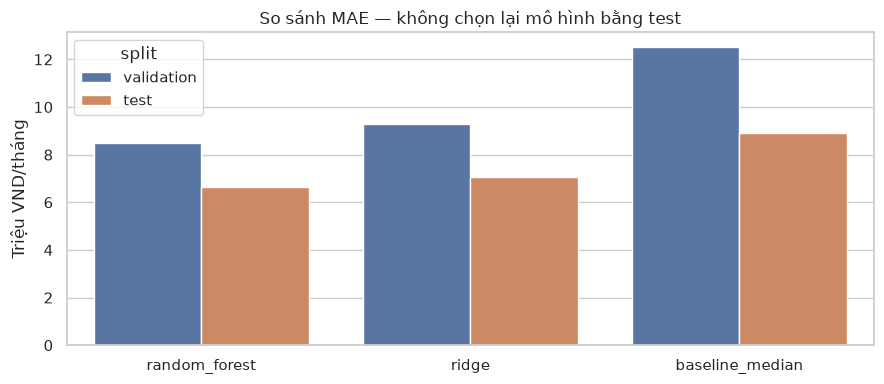

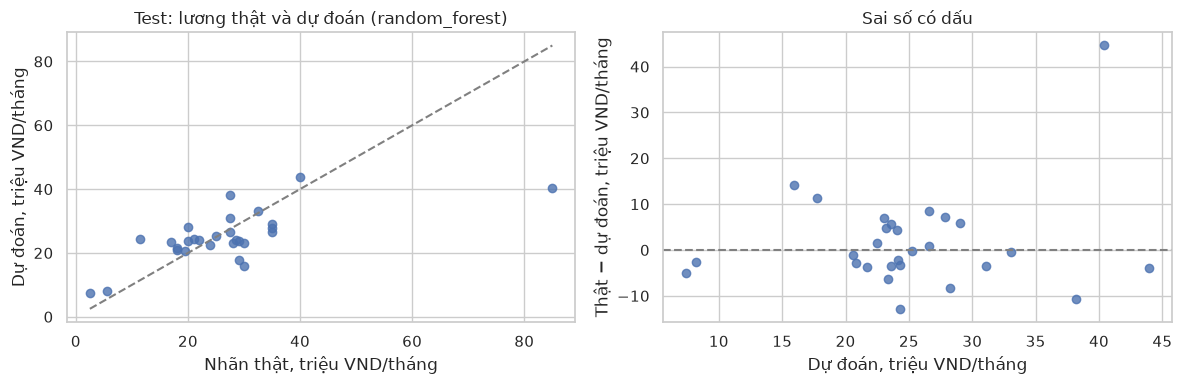

In [13]:
def save_model_chart(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

comparison = pd.concat([validation_table.assign(split="validation"),
                        test_table.assign(split="test")], ignore_index=True)
comparison["mae_million"] = comparison["mae_vnd"] / 1_000_000
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=comparison, x="model", y="mae_million", hue="split", errorbar=None, ax=ax)
ax.set(title="So sánh MAE — không chọn lại mô hình bằng test", xlabel="", ylabel="Triệu VND/tháng")
save_model_chart(fig, "mae_comparison")

actual = test_predictions["actual_vnd"] / 1_000_000
predicted = test_predictions[f"pred_{selected_name}_vnd"] / 1_000_000
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(actual, predicted, alpha=0.8)
limits = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
axes[0].plot(limits, limits, "--", color="gray")
axes[0].set(title=f"Test: lương thật và dự đoán ({selected_name})",
            xlabel="Nhãn thật, triệu VND/tháng", ylabel="Dự đoán, triệu VND/tháng")
axes[1].scatter(predicted, actual - predicted, alpha=0.8)
axes[1].axhline(0, linestyle="--", color="gray")
axes[1].set(title="Sai số có dấu", xlabel="Dự đoán, triệu VND/tháng",
            ylabel="Thật − dự đoán, triệu VND/tháng")
save_model_chart(fig, "test_predictions_and_residuals")


## 14. Phân tích lỗi test và độ bất định

Đây là phân tích sau đánh giá để ghi giới hạn, không dùng sửa model rồi báo lại cùng test
như một đánh giá độc lập. MAE bootstrap chỉ mô tả độ bất định của mẫu test nhỏ hiện tại,
không bao gồm mọi sai lệch nguồn hoặc lỗi nhãn.

In [14]:
errors = test_predictions.copy()
errors["predicted_vnd"] = errors[f"pred_{selected_name}_vnd"]
errors["absolute_error_vnd"] = (errors["actual_vnd"] - errors["predicted_vnd"]).abs()
display(errors.sort_values("absolute_error_vnd", ascending=False).head(10))
slice_errors = errors.groupby("role").agg(
    test_rows=("record_id", "size"), mae_vnd=("absolute_error_vnd", "mean"))
display(slice_errors)
print("Không kết luận chất lượng riêng cho vai trò chỉ có 1–vài mẫu.")
errors.to_csv(OUT / "test_errors.csv", index=False)
slice_errors.to_csv(OUT / "test_errors_by_role.csv")

rng = np.random.default_rng(SEED)
absolute_errors = errors["absolute_error_vnd"].to_numpy()
bootstrap_mae = rng.choice(absolute_errors, size=(2000, len(absolute_errors)), replace=True).mean(axis=1)
ci = np.quantile(bootstrap_mae, [0.025, 0.975])
print(f"Khoảng percentile bootstrap MAE 95%: {ci[0]/1e6:.2f}–{ci[1]/1e6:.2f} triệu VND/tháng")
(OUT / "mae_bootstrap.json").write_text(json.dumps({
    "model": selected_name, "test_rows": len(errors), "resamples": 2000,
    "low_vnd": float(ci[0]), "high_vnd": float(ci[1]),
    "scope": "conditional on this small test sample; not all data/source uncertainty",
}, indent=2) + "\n")


,record_id,leakage_group_id,role,source_dataset,actual_vnd,pred_baseline_median_vnd,pred_ridge_vnd,pred_random_forest_vnd,predicted_vnd,absolute_error_vnd
0,user_vietnam_it_jobs:3897,ce282a4e14e3968eea00f3c26a4b65e5c4916ebcbc46f3d7329f3aa348b658cd,Full-stack Developer,user_vietnam_it_jobs,8.500000e+07,24000000.0,4.988460e+07,4.040675e+07,4.040675e+07,4.459325e+07
4,vietjobs_2025:17361,f7e07b3f7224e328d5540ced5f1c88e8e350e6f70abe56ab2812cabd86b1c464,Software Developer,vietjobs_2025,3.000000e+07,24000000.0,1.361141e+07,1.591415e+07,1.591415e+07,1.408585e+07
18,vietjobs_2025:18534,42996633c5cef95bf60ed6558d45bfff838787afb6cac8b5538a21ab5d85d06e,Mobile Developer,vietjobs_2025,1.150000e+07,24000000.0,1.865961e+07,2.433031e+07,2.433031e+07,1.283031e+07
1,user_vietnam_it_jobs:3993,95a904d196f358b66a506b1ff00d459fb0fa169a11a2394c87d69d8eb8b8d351,Frontend Developer,user_vietnam_it_jobs,2.916667e+07,24000000.0,1.760795e+07,1.776876e+07,1.776876e+07,1.139791e+07
11,vietjobs_2025:17719,7049f5271c33dde0abcc45c01cf814cdc84d386865da16b8921cbf261f8a2774,Frontend Developer,vietjobs_2025,2.750000e+07,24000000.0,4.025424e+07,3.818424e+07,3.818424e+07,1.068424e+07
27,vietjobs_2025:19250,c431dd65f0eea66b49fe38f99344c999c770305de96a3e3b242be9bad4b9930c,Data Engineer,vietjobs_2025,3.500000e+07,24000000.0,3.098002e+07,2.655296e+07,2.655296e+07,8.447043e+06
13,vietjobs_2025:17859,8ed187bb6fd0e2d9ba961240a94b27f5f9743b9e65109574906315c52f5b412b,Backend Developer,vietjobs_2025,2.000000e+07,24000000.0,3.047559e+07,2.821465e+07,2.821465e+07,8.214652e+06
19,vietjobs_2025:18568,5c018fbed58debe2714a3d2e688d9d0673b87f310e6dc9bf0f6f82a8c0dd0f20,Backend Developer,vietjobs_2025,3.500000e+07,24000000.0,3.055618e+07,2.785592e+07,2.785592e+07,7.144081e+06
25,vietjobs_2025:18944,cdf6670918dd911f2b23dd516e75cf8d53e911ba2f34ea954651d3f9b0019886,Mobile Developer,vietjobs_2025,3.000000e+07,24000000.0,1.888862e+07,2.303080e+07,2.303080e+07,6.969205e+06
17,vietjobs_2025:18468,2073dfe2dc7aa1656b1ab53ae85d7279c7bbf23f85a7b6ff0f00372a83c258ae,Frontend Developer,vietjobs_2025,1.700000e+07,24000000.0,2.383783e+07,2.332341e+07,2.332341e+07,6.323407e+06


,test_rows,mae_vnd
role,,
Backend Developer,4,4.342540e+06
Data Engineer,1,8.447043e+06
Embedded Engineer,1,3.601483e+06
Frontend Developer,6,5.625048e+06
Full-stack Developer,4,1.466748e+07
ML Engineer,1,2.160675e+06
Mobile Developer,4,5.904828e+06
Software Developer,7,5.537066e+06


Không kết luận chất lượng riêng cho vai trò chỉ có 1–vài mẫu.
Khoảng percentile bootstrap MAE 95%: 4.29–10.16 triệu VND/tháng


222

## 15. Kỹ năng liên hệ với mức lương — hệ số Ridge có điều kiện

Chỉ dùng features và số lần xuất hiện trong **train**. Hệ số của token kỹ năng thể hiện
liên hệ trong mô hình Ridge đã regularize, có điều kiện theo các feature khác. Kỹ năng
đồng xuất hiện làm hệ số thiếu ổn định; không gọi đây là mức lương tăng do học kỹ năng.
Hiển thị cả số mẫu hỗ trợ, chỉ chọn token có ít nhất 5 dòng train.

,skill,train_rows,coefficient_vnd
314,python,33,1.830093e+06
199,jira,6,1.074401e+06
27,.net core,6,8.508367e+05
26,.net,9,7.490687e+05
99,dart,6,5.158459e+05
371,spring boot,9,4.904920e+05
318,rabbitmq,8,3.765602e+05
60,aws,5,2.123039e+05
388,svn,6,1.255072e+05
378,sql,11,-3.789832e+04


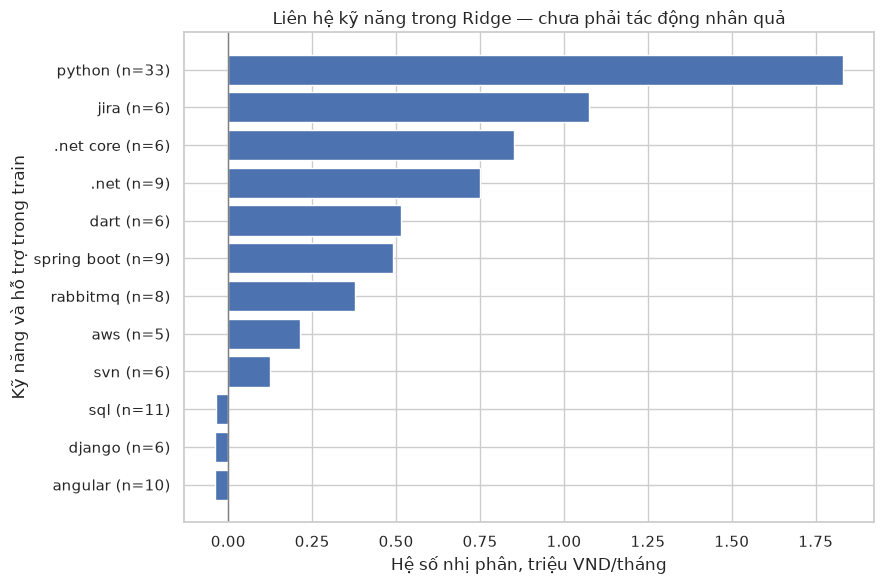

In [15]:
ridge_pipeline = best_ridge["pipeline"]
fitted_preprocessor = ridge_pipeline.named_steps["preprocess"]
feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = np.ravel(ridge_pipeline.named_steps["model"].coef_)
coef_table = pd.DataFrame({"feature": feature_names, "coefficient_vnd": coefficients})
skill_encoder = fitted_preprocessor.named_transformers_["skills"]
skill_names = skill_encoder.named_steps["vectorizer"].get_feature_names_out()
skill_support = np.asarray(skill_encoder.transform(X_train[["skills"]]).sum(axis=0)).ravel()
support_map = dict(zip(skill_names, skill_support.astype(int)))
skill_coefficients = coef_table[coef_table["feature"].str.startswith("skills__")].copy()
skill_coefficients["skill"] = skill_coefficients["feature"].str.removeprefix("skills__")
skill_coefficients["train_rows"] = skill_coefficients["skill"].map(support_map)
skill_coefficients = skill_coefficients[skill_coefficients["train_rows"].ge(5)]
skill_coefficients = skill_coefficients.sort_values("coefficient_vnd", ascending=False)
display(skill_coefficients[["skill", "train_rows", "coefficient_vnd"]].head(15))
skill_coefficients.to_csv(OUT / "ridge_skill_associations_train.csv", index=False)
top = skill_coefficients.head(12).sort_values("coefficient_vnd")
if len(top):
    fig, ax = plt.subplots(figsize=(9, 6))
    labels = [f"{skill} (n={n})" for skill, n in zip(top["skill"], top["train_rows"])]
    ax.barh(labels, top["coefficient_vnd"] / 1_000_000)
    ax.axvline(0, color="gray", linewidth=1)
    ax.set(title="Liên hệ kỹ năng trong Ridge — chưa phải tác động nhân quả",
           xlabel="Hệ số nhị phân, triệu VND/tháng", ylabel="Kỹ năng và hỗ trợ trong train")
    save_model_chart(fig, "ridge_skill_associations_train")


## 16. Nạp model và thử một hồ sơ minh họa

Hồ sơ dưới đây không phải test case có nhãn thật. Dự đoán chỉ minh họa cách gọi model,
không dùng làm metric. Thay các giá trị để thử sau khi hoàn tất đánh giá.

In [16]:
profile = pd.DataFrame([{
    "experience_years": 3.0,
    "role": "Backend Developer",
    "level": "Junior",
    "location": "Hà Nội",
    "skills": "Python;SQL;Docker",
}])
loaded_model = joblib.load(MODEL_DIR / "best_model.joblib")
demo_prediction = float(loaded_model.predict(features_from(profile))[0])
display(profile)
print(f"Model {selected_name}: khoảng {demo_prediction / 1e6:.2f} triệu VND/tháng (ước tính điểm).")
if demo_prediction < 0:
    print("Model trả giá trị âm, không hợp lý cho hồ sơ này; ghi nhận giới hạn, không âm thầm sửa metric.")

# Kiểm tra artifact nạp được trong một Python process mới, không có hàm của kernel notebook.
probe = """import sys, json, joblib, pandas as pd
model = joblib.load(sys.argv[1])
profile = pd.DataFrame(json.loads(sys.argv[2]))
print(float(model.predict(profile)[0]))
"""
completed = subprocess.run([sys.executable, "-c", probe, str(MODEL_DIR / "best_model.joblib"),
                            profile.to_json(orient="records")], capture_output=True, text=True, check=True)
np.testing.assert_allclose(float(completed.stdout.strip()), demo_prediction)
print("Đã xác nhận nạp và dự đoán trong Python process mới.")


,experience_years,role,level,location,skills
0,3.0,Backend Developer,Junior,Hà Nội,Python;SQL;Docker


Model random_forest: khoảng 31.95 triệu VND/tháng (ước tính điểm).


Đã xác nhận nạp và dự đoán trong Python process mới.


## 17. Xuất tóm tắt cho báo cáo và kiểm tra dữ liệu không đổi

Đưa cả baseline và hai mô hình vào báo cáo, kể cả khi R² âm hoặc không vượt baseline.
Phân biệt kết quả validation để chọn mô hình với kết quả test cuối. Kết quả ở đây không
chứng minh dự đoán tương lai hoặc mức tăng thu nhập nhân quả của kỹ năng.

In [17]:
for split in ["train", "valid", "test"]:
    info = manifest["files"][split]
    assert sha256_file(ROOT / info["path"]) == info["sha256"], "Dữ liệu đóng băng đã thay đổi."

summary_lines = [
    f"# Kết quả thực nghiệm lương — {EXPERIMENT_ID}", "",
    "Bộ vn_developer v1.0.1; nhãn trung điểm lương VND/tháng, chưa rõ gross/net.",
    f"Train {len(train_df)} / validation {len(valid_df)} / test {len(test_ids)}.",
    f"Chọn bằng MAE validation: {selected_name}. Fit preprocessing/model chỉ trên train.", "",
    "| Model | Test MAE (triệu) | Test RMSE (triệu) | Test R² |",
    "|---|---:|---:|---:|",
]
for row in test_table.itertuples():
    summary_lines.append(f"| {row.model} | {row.mae_vnd/1e6:.3f} | {row.rmse_vnd/1e6:.3f} | {row.r2:.3f} |")
summary_lines += ["", "Không đổi lựa chọn model bằng test; baseline được báo cáo đầy đủ.",
    "Giới hạn: 28 mẫu test; snapshot hỗn hợp 2025–2026, nhãn nguồn chưa phải gold,",
    "chưa kiểm thử thời gian hoặc xác minh khả năng tổng quát toàn thị trường.",
    "Liên hệ kỹ năng không phải tác động nhân quả.", "",
    f"Model: models/salary/{EXPERIMENT_ID}/best_model.joblib",
    "Bằng chứng: protocol.json, selection.json, validation_metrics.csv, test_metrics.csv,",
    "test_predictions.csv, test_errors.csv và các biểu đồ trong cùng thư mục."]
(OUT / "REPORT.md").write_text("\n".join(summary_lines) + "\n")
display(Markdown("\n".join(summary_lines)))
print("Báo cáo:", OUT / "REPORT.md")
print("Model:", MODEL_DIR / "best_model.joblib")


# Kết quả thực nghiệm lương — bd9af2fa002caae8

Bộ vn_developer v1.0.1; nhãn trung điểm lương VND/tháng, chưa rõ gross/net.
Train 123 / validation 25 / test 28.
Chọn bằng MAE validation: random_forest. Fit preprocessing/model chỉ trên train.

| Model | Test MAE (triệu) | Test RMSE (triệu) | Test R² |
|---|---:|---:|---:|
| baseline_median | 8.921 | 14.339 | -0.033 |
| ridge | 7.074 | 9.603 | 0.537 |
| random_forest | 6.656 | 10.517 | 0.444 |

Không đổi lựa chọn model bằng test; baseline được báo cáo đầy đủ.
Giới hạn: 28 mẫu test; snapshot hỗn hợp 2025–2026, nhãn nguồn chưa phải gold,
chưa kiểm thử thời gian hoặc xác minh khả năng tổng quát toàn thị trường.
Liên hệ kỹ năng không phải tác động nhân quả.

Model: models/salary/bd9af2fa002caae8/best_model.joblib
Bằng chứng: protocol.json, selection.json, validation_metrics.csv, test_metrics.csv,
test_predictions.csv, test_errors.csv và các biểu đồ trong cùng thư mục.

Báo cáo: /Users/scara2906/Downloads/ML/outputs/metrics/salary_bd9af2fa002caae8/REPORT.md
Model: /Users/scara2906/Downloads/ML/models/salary/bd9af2fa002caae8/best_model.joblib
